# Decision Tree

This notebook walks through the Decision Tree pipeline end-to-end: data loading, feature construction, bounded group-CV tuning, validation evaluation, metrics, and interpretation.

## 1. Load prepared data and fixed splits

Loads the prepared development bundle through the project's shared splitter. Only train and validation partitions are used; the locked test partition is never materialized during development selection.

In [1]:
import warnings
import time
import json
import numpy as np
import pandas as pd
from pathlib import Path
import sys
# Find project root (directory containing src/). Run from project root or
# nbconvert will still locate it via the marker file below.
import os
_cwd = Path.cwd()
_roots = [_cwd]
for _p in [_cwd, _cwd.parent, _cwd.parent.parent, _cwd.parent.parent.parent]:
    if (_p / "src" / "splitting.py").exists():
        _roots.insert(0, _p)
        break
ROOT = _roots[0]
sys.path.insert(0, str(ROOT))
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from src.splitting import load_development_bundle

LABELS = ["Safe", "Neutral", "Risky"]

# 1. Load prepared data and fixed splits (primary protocol; validation is held-out).
data, split_meta = load_development_bundle("primary", ROOT)
print("Split:", split_meta["split_id"])
print("Dataset SHA-256:", split_meta["dataset_sha256"])

train = data[data["primary_partition"].eq("train") & data["primary_include"]].copy().reset_index(drop=True)
validation = data[data["primary_partition"].eq("validation") & data["primary_include"]].copy().reset_index(drop=True)

print("Train rows:", len(train))
print("Validation rows:", len(validation))
print("Train label counts:")
print(train["label"].value_counts())
print("Validation label counts:")
print(validation["label"].value_counts())

# Group-respecting CV folds come from the frozen manifest (primary_cv_fold).
folds = sorted(train["primary_cv_fold"].unique().tolist())
print("CV folds:", folds)


Split: split_manifest_v1
Dataset SHA-256: cee557cc927d754cf17675154ed5e1e32eee2fdb9af6700c526e62cd66969f8c
Train rows: 13439
Validation rows: 2658
Train label counts:
label
Neutral    5669
Risky      4402
Safe       3368
Name: count, dtype: int64
Validation label counts:
label
Neutral    1104
Risky       864
Safe        690
Name: count, dtype: int64
CV folds: [0, 1, 2]


## 2. Build the feature/model pipeline (TF-IDF + TruncatedSVD-100 dense)

Fits TF-IDF on training data only, then fits a training-fold TruncatedSVD (100 components) to produce dense input. SVD is a feature transform, not a classifier, and is fitted on training data only.

In [2]:
# 2. Build the feature/model pipeline (TF-IDF + TruncatedSVD-100 dense).
# SVD is fitted on training data only; it is a feature transform, not a classifier.
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

vectorizer = TfidfVectorizer(
    analyzer="word", ngram_range=(1, 2), min_df=2, max_df=0.99,
    max_features=60000, sublinear_tf=True, strip_accents="unicode",
    dtype=np.float32, lowercase=True,
)
X_train_sparse = vectorizer.fit_transform(train["quote_text"].fillna("").astype(str))
X_val_sparse = vectorizer.transform(validation["quote_text"].fillna("").astype(str))

svd = TruncatedSVD(n_components=100, n_iter=5, random_state=20261102)
X_train = svd.fit_transform(X_train_sparse).astype(np.float32, copy=False)
X_val = svd.transform(X_val_sparse).astype(np.float32, copy=False)

print("Dense train shape:", X_train.shape)
print("Dense validation shape:", X_val.shape)


Dense train shape: (13439, 100)
Dense validation shape: (2658, 100)


In [3]:
# 3. Train, bounded tune, and predict on validation.
# Uses the three fixed group-respecting CV folds; TF-IDF/SVD refit inside each fold.
from sklearn.tree import DecisionTreeClassifier
MODEL_CLASS = lambda **p: DecisionTreeClassifier(random_state=20261102, **p)
GRID = [{"max_depth": d, "min_samples_leaf": l, "ccp_alpha": a, "class_weight": "balanced"} for d in (15, 30, None) for l in (2, 10) for a in (0.0, 0.001)]

XTR = X_train
XVA = X_val
YTR = train["label"].to_numpy()
YVA = validation["label"].to_numpy()

fold_series = train["primary_cv_fold"].to_numpy()
best = None
fold_details = []
for params in GRID:
    fold_scores = []
    for fold in folds:
        fit_mask = fold_series != fold
        eval_mask = fold_series == fold
        model = MODEL_CLASS(**params)
        with warnings.catch_warnings(record=True):
            warnings.simplefilter("always")
            model.fit(XTR[fit_mask], YTR[fit_mask])
        yp = model.predict(XTR[eval_mask])
        fold_scores.append(f1_score(YTR[eval_mask], yp, labels=LABELS, average="macro", zero_division=0))
    mean_score = float(np.mean(fold_scores))
    std_score = float(np.std(fold_scores, ddof=1)) if len(fold_scores) > 1 else 0.0
    print(params, "-> CV macro F1:", round(mean_score, 4), "±", round(std_score, 4))
    fold_details.append({"params": params, "mean_cv": mean_score, "std_cv": std_score, "folds": fold_scores})
    if best is None or mean_score > best["mean_cv"]:
        best = {"params": params, "mean_cv": mean_score, "std_cv": std_score, "folds": fold_scores}

print()
print("Best params:", best["params"], "CV macro F1:", round(best["mean_cv"], 4), "±", round(best["std_cv"], 4))

final = MODEL_CLASS(**best["params"])
t0 = time.perf_counter()
final.fit(XTR, YTR)
fit_seconds = time.perf_counter() - t0

# Train performance (overfitting diagnosis — not used for selection).
y_train_pred = final.predict(XTR)
train_acc = float(accuracy_score(YTR, y_train_pred))
train_f1 = float(f1_score(YTR, y_train_pred, labels=LABELS, average="macro", zero_division=0))

t0 = time.perf_counter()
y_pred = final.predict(XVA)
predict_seconds = time.perf_counter() - t0

print("Fit seconds:", round(fit_seconds, 3))
print("Predict seconds:", round(predict_seconds, 3))
print("Train macro F1:", round(train_f1, 4))
print("Train accuracy:", round(train_acc, 4))


{'max_depth': 15, 'min_samples_leaf': 2, 'ccp_alpha': 0.0, 'class_weight': 'balanced'} -> CV macro F1: 0.6402 ± 0.0167


{'max_depth': 15, 'min_samples_leaf': 2, 'ccp_alpha': 0.001, 'class_weight': 'balanced'} -> CV macro F1: 0.6626 ± 0.002


{'max_depth': 15, 'min_samples_leaf': 10, 'ccp_alpha': 0.0, 'class_weight': 'balanced'} -> CV macro F1: 0.6533 ± 0.0082


{'max_depth': 15, 'min_samples_leaf': 10, 'ccp_alpha': 0.001, 'class_weight': 'balanced'} -> CV macro F1: 0.6627 ± 0.0018


{'max_depth': 30, 'min_samples_leaf': 2, 'ccp_alpha': 0.0, 'class_weight': 'balanced'} -> CV macro F1: 0.633 ± 0.0164


{'max_depth': 30, 'min_samples_leaf': 2, 'ccp_alpha': 0.001, 'class_weight': 'balanced'} -> CV macro F1: 0.6627 ± 0.0018


... (3 outputs left out)

{'max_depth': None, 'min_samples_leaf': 2, 'ccp_alpha': 0.001, 'class_weight': 'balanced'} -> CV macro F1: 0.6627 ± 0.0018


{'max_depth': None, 'min_samples_leaf': 10, 'ccp_alpha': 0.0, 'class_weight': 'balanced'} -> CV macro F1: 0.6536 ± 0.0068


{'max_depth': None, 'min_samples_leaf': 10, 'ccp_alpha': 0.001, 'class_weight': 'balanced'} -> CV macro F1: 0.6627 ± 0.0018

Best params: {'max_depth': 15, 'min_samples_leaf': 10, 'ccp_alpha': 0.001, 'class_weight': 'balanced'} CV macro F1: 0.6627 ± 0.0018


Fit seconds: 1.598
Predict seconds: 0.001
Train macro F1: 0.6953
Train accuracy: 0.6998


## 4. Calculate metrics on held-out validation

Computes accuracy, balanced accuracy, per-class precision/recall/F1/support, macro and weighted averages, Risky false positives/false negatives, and the confusion matrix.

In [4]:
# 4. Calculate metrics on held-out validation.
report = classification_report(YVA, y_pred, labels=LABELS, output_dict=True, zero_division=0)

summary = {
    "rows": int(len(YVA)),
    "accuracy": float(accuracy_score(YVA, y_pred)),
    "balanced_accuracy": float(balanced_accuracy_score(YVA, y_pred)),
    "macro_f1": float(f1_score(YVA, y_pred, labels=LABELS, average="macro", zero_division=0)),
    "macro_precision": float(precision_score(YVA, y_pred, labels=LABELS, average="macro", zero_division=0)),
    "macro_recall": float(recall_score(YVA, y_pred, labels=LABELS, average="macro", zero_division=0)),
    "risky_precision": float(precision_score(YVA, y_pred, labels=["Risky"], average="macro", zero_division=0)),
    "risky_recall": float(recall_score(YVA, y_pred, labels=["Risky"], average="macro", zero_division=0)),
    "risky_false_positives": int(((YVA != "Risky") & (y_pred == "Risky")).sum()),
    "risky_false_negatives": int(((YVA == "Risky") & (y_pred != "Risky")).sum()),
}
for label in LABELS:
    summary[f"{label.lower()}_precision"] = float(report[label]["precision"])
    summary[f"{label.lower()}_recall"] = float(report[label]["recall"])
    summary[f"{label.lower()}_f1"] = float(report[label]["f1-score"])
    summary[f"{label.lower()}_support"] = float(report[label]["support"])

print(json.dumps(summary, indent=2))

cm = confusion_matrix(YVA, y_pred, labels=LABELS)
cm_df = pd.DataFrame(cm, index=[f"true_{l}" for l in LABELS], columns=[f"pred_{l}" for l in LABELS])
print(cm_df)


{
  "rows": 2658,
  "accuracy": 0.63732129420617,
  "balanced_accuracy": 0.6433407139023081,
  "macro_f1": 0.6344427855573861,
  "macro_precision": 0.638103083583255,
  "macro_recall": 0.6433407139023082,
  "risky_precision": 0.6091954022988506,
  "risky_recall": 0.6747685185185185,
  "risky_false_positives": 374,
  "risky_false_negatives": 281,
  "safe_precision": 0.541371158392435,
  "safe_recall": 0.663768115942029,
  "safe_f1": 0.5963541666666666,
  "safe_support": 690.0,
  "neutral_precision": 0.7637426900584795,
  "neutral_recall": 0.5914855072463768,
  "neutral_f1": 0.6666666666666666,
  "neutral_support": 1104.0,
  "risky_f1": 0.6403075233388248,
  "risky_support": 864.0
}
              pred_Safe  pred_Neutral  pred_Risky
true_Safe           458            97         135
true_Neutral        212           653         239
true_Risky          176           105         583


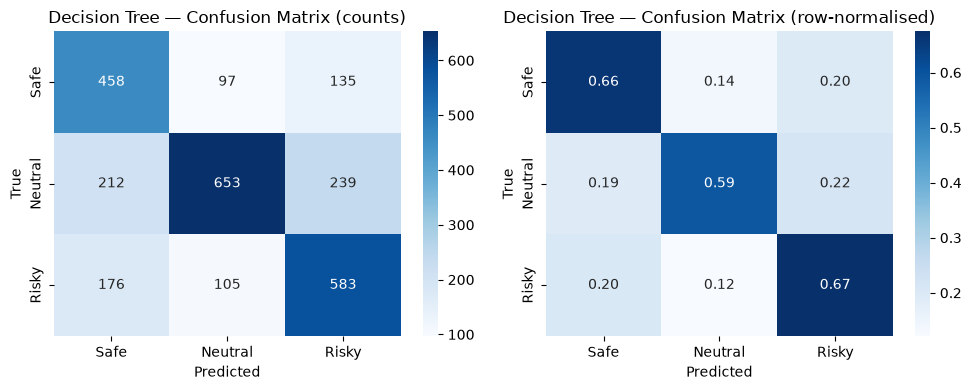

In [5]:
# 5. Plot confusion matrix (counts + row-normalised).
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=LABELS, yticklabels=LABELS, ax=axes[0])
axes[0].set_title("Decision Tree — Confusion Matrix (counts)")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")

cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=LABELS, yticklabels=LABELS, ax=axes[1])
axes[1].set_title("Decision Tree — Confusion Matrix (row-normalised)")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("True")

plt.tight_layout()
plt.show()


## 6. Interpretation

- Reported scores are on the **validation** partition of the **primary** protocol (development data only).
- CV macro F1 was computed on the three fixed group-respecting development folds; TF-IDF/SVD were refit inside each fold.
- The locked test partition was not used for tuning or selection.
- Macro F1 treats all three classes equally; Risky precision/recall are reported alongside.
- Train macro F1 is shown for overfitting diagnosis only; it is not used for selection.
- Coefficients/rules are associations from case-derived annotations — not legal advice.
- A missing Risky prediction does not establish that a document is safe.

Saved results: `models/decision_tree/results/primary/metrics.csv`
Canonical comparison: `results/comparison/primary/comparison.csv`
